# Title of your project

#### Student name(s): Ousmane DIALLO

## Abstract <a class="anchor" id="problem"></a>

This project focuses on using machine learning-based classification algorithms to identify seven variety of dry beans based on their geometric
characteristics. The "Dry Bean Dataset" is sourced from the UCI Machine Learning website and contains 13,611 observations, with 16 numerical features
describing the shape and size of the beans. Four classification models-logistic regression, decision tree, random forest, and support vector machine
will be trained and compared. To valuate these models, the project employs techniques such as data preprocessing, stratified cross-validation, and various performance metrics, including accuracy, macro F1-score, precision, and recall. Additionally, permutation feature importance will be used to identify which characteristics contribute most to predictive performance, with the aim of enhancing the efficiency of the machine algorithms. the ultimate goal is to select a reliable classification model while gaining insight into which geometric features are most useful for distinguishing between the different bean varieties.

## Table of Content

[Problem](#problem)   
[Data Understanding](#data_understanding)   
[Data Preparation](#data_preparation)   
[Modeling](#modeling)   
[Evaluation](#evaluation)   
[References](#references)   


## Problem <a class="anchor" id="problem"></a>

Describe the problem here. What are the questions you are trying to solve?
Identifying dry bean varieties based on their physical characteristics is a significant classification problem in agricultural data analysis, as the 
ability to distinguish between different types of beans is essential for understanding their origin, maturation, and properties. Since manual identification can be tedious, a machine learning model could offer a more consistent and efficient alternative. The variety of dry bean based on its 
numerical measurements. 
The research addresses the following topics:
To what extent can machine learning models classify seven varieties of dry beans with such high precision?
Among logistic regression, decision trees, random forests, support vector machines (SVM), which model achieves the best performance?
What are the most appropriate evaluation metrics when the target classes are imbalanced?
Does features selection allow for a reducion in the number of input variable without a significant decline in predictive performance?


## Data Understanding<a class="anchor" id="data_understanding"></a>

The Dry Bean Dataset come from the website UCI Machine learning. The contains of this data is approximative 13,611 by our observation. We have 16 
numerical for predictor features. The variable of taget Class are identifies by many varieties of dry beans such as The Barbunya, Bomboay, Cali, 
Dermason, Horoz, Seker, and Sira bean varieties.they are characterize their size, shape, and geometric properties.  

In [1]:
from pathlib import Path
import io,zipfile,urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay,confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score    

RANDOM_STATE = 42
sns.set_theme(style="whitegrid",context="notebook")
pd.set_option("display.max_columns",30)
pd.set_option("display.width",120)
DATA_URL= "https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.zip"
print("loading data from UC Irvine Machine Learning Repository")
with urllib.request.urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as zf:
    xlsx_path = next(n for n in zf.namelist() if n.lower().endswith(".xlsx"))
    with zf.open(xlsx_path) as file:
        df = pd.read_excel(file)
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"AspectRation":"Aspectio"})
TARGET="Class"
assert TARGET in df.columns, f"Expected target column {TARGET!r}; found{df.columns.tolist()}"
X=df.drop(columns=TARGET)
Y=df[TARGET].astype(str)
print(f"Dataset shape: {df.shape[0]:,} row * {df.shape[1]} columns")
display(df.head())
display(pd.DataFrame({
    "dtype":df.dtypes.astype(str),
    "missing_count":df.isna().sum(),
    "missing_percent":(df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}))
display(df.describe().T.round(3))
display(Y.value_counts().rename_axis("Bean variety").to_frame("Count"))
print("The exact duplicate rows:", int(df.duplicated().sum()))


loading data from UC Irvine Machine Learning Repository
Dataset shape: 13,611 row * 17 columns


,Area,Perimeter,MajorAxisLength,MinorAxisLength,Aspectio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,dtype,missing_count,missing_percent,unique_values
Area,int64,0,0.0,12011
Perimeter,float64,0,0.0,13416
MajorAxisLength,float64,0,0.0,13543
MinorAxisLength,float64,0,0.0,13543
Aspectio,float64,0,0.0,13543
Eccentricity,float64,0,0.0,13543
ConvexArea,int64,0,0.0,12066
EquivDiameter,float64,0,0.0,12011
Extent,float64,0,0.0,13535
Solidity,float64,0,0.0,13526


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
Aspectio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


,Count
Bean variety,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


The exact duplicate rows: 68


## Exploration of our Data Analysis<a class="anchor" id="data_exploration"></a>

Before training the models, an exploratory data analysis(EDA) is conducted to understand the distribution of and relationships between the variables.
This analysis includes:
examining the number of observations and predictive variables;
checking for missing values and duplicate rows;
calculating descriptive statistics such as the mean, standard deviation, minimum, and maximum;
visualizing the distribution of numerical feature using histograms and box plots.
examining the distribution of the seven target classes using a count plot;
studying the corralation between the numerical features using a corralation heatmap

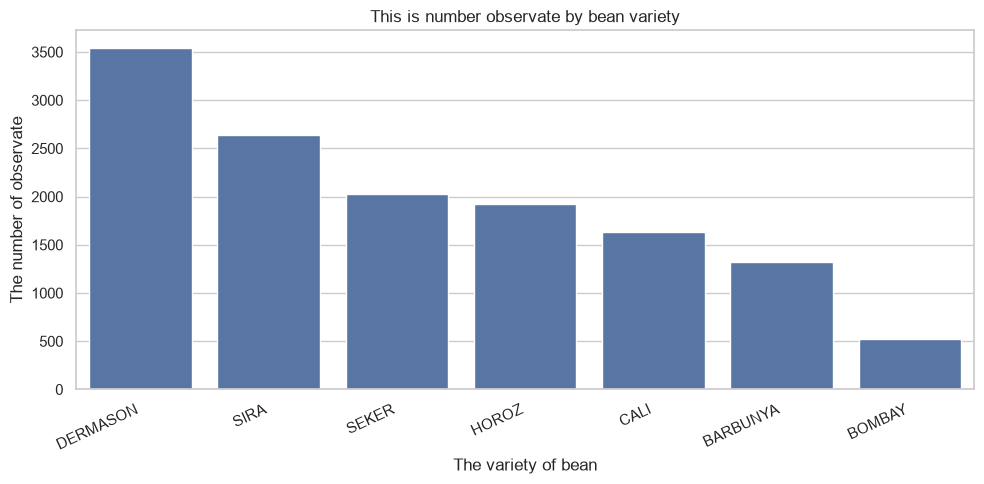

In [2]:
#This is for class Distribution
plt.figure(figsize=(10,5))
order = Y.value_counts().index
sns.countplot(data=df, x=TARGET, order=order)
plt.title("This is number observate by bean variety")
plt.xlabel("The variety of bean"); 
plt.ylabel("The number of observate")
plt.xticks(rotation=25, ha="right"); 
plt.tight_layout(); 
plt.show()

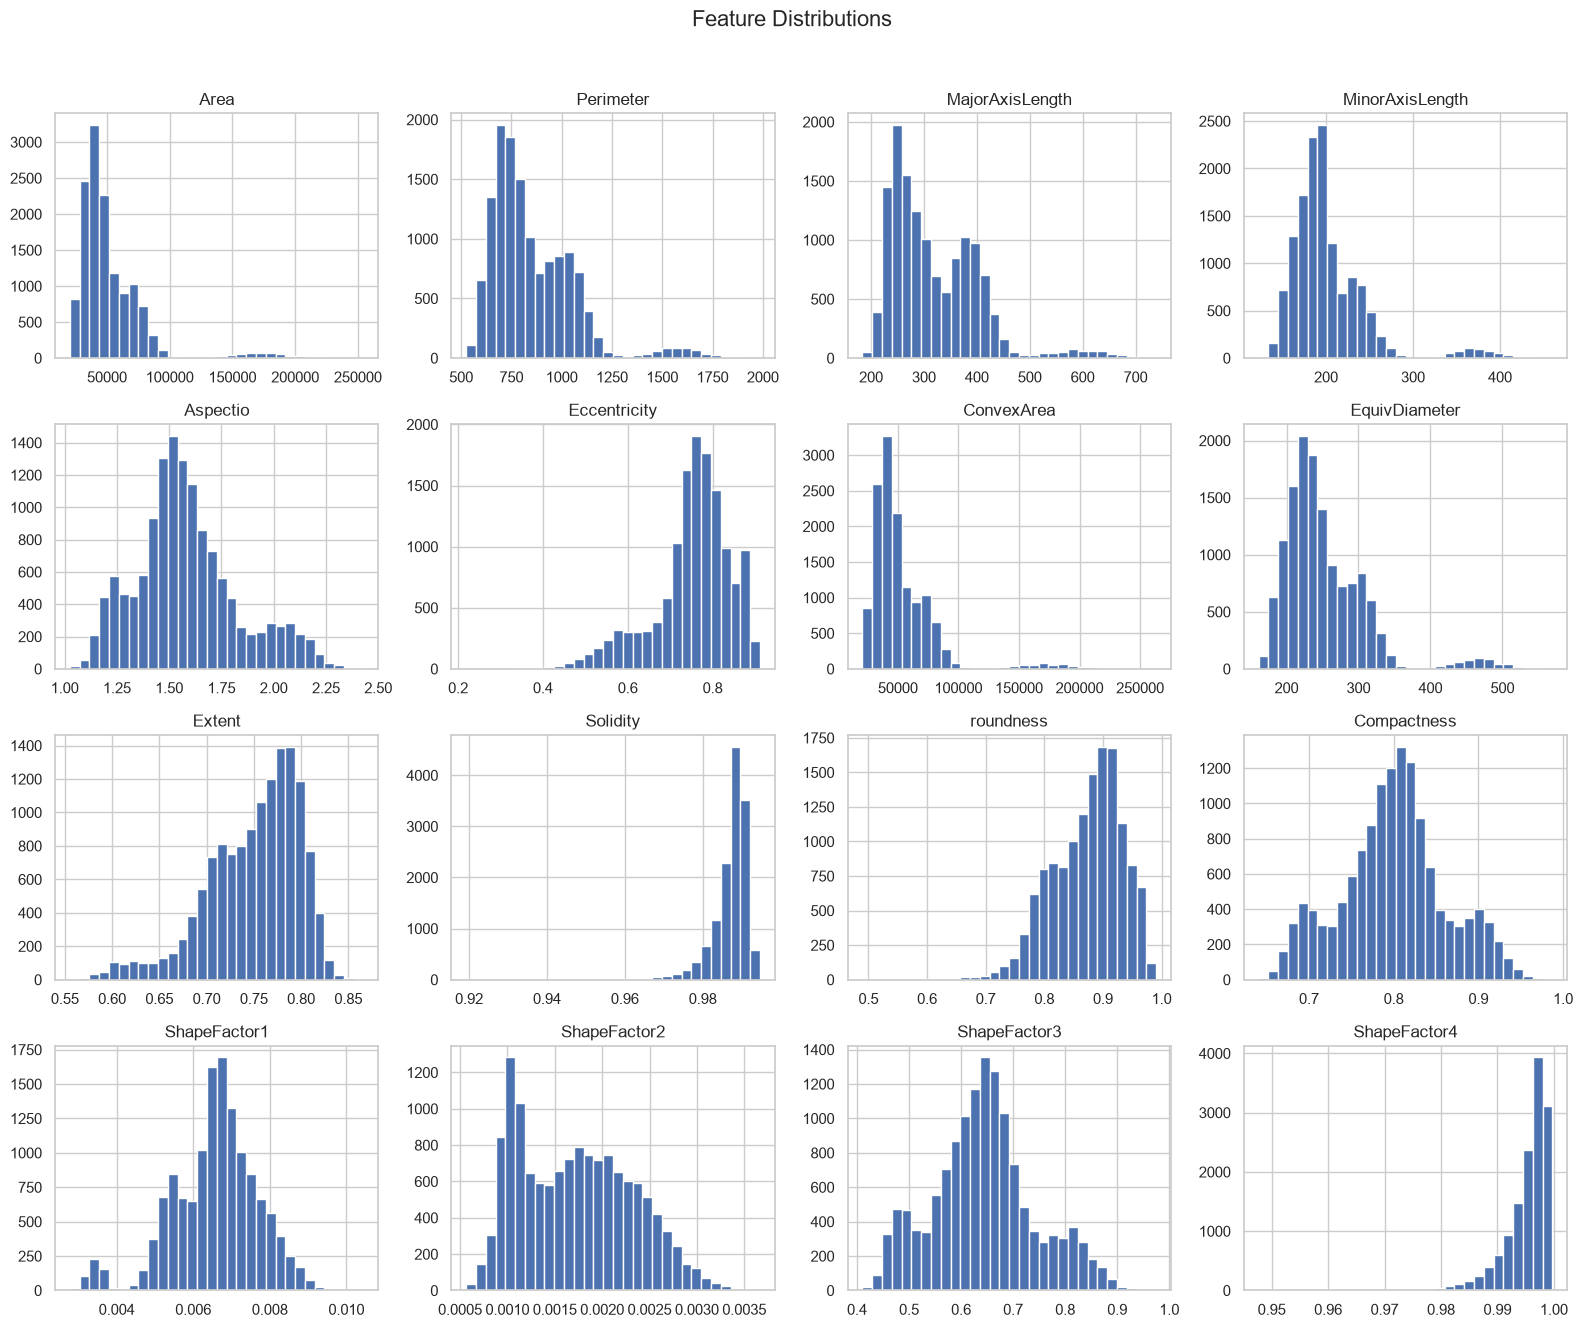

In [3]:
#This is for distributions of all numeric features
df[X.columns].hist(figsize=(16,13), bins=30,edgecolor="white")
plt.suptitle("Feature Distributions", y=1.02, fontsize=16)
plt.tight_layout(); 
plt.show()

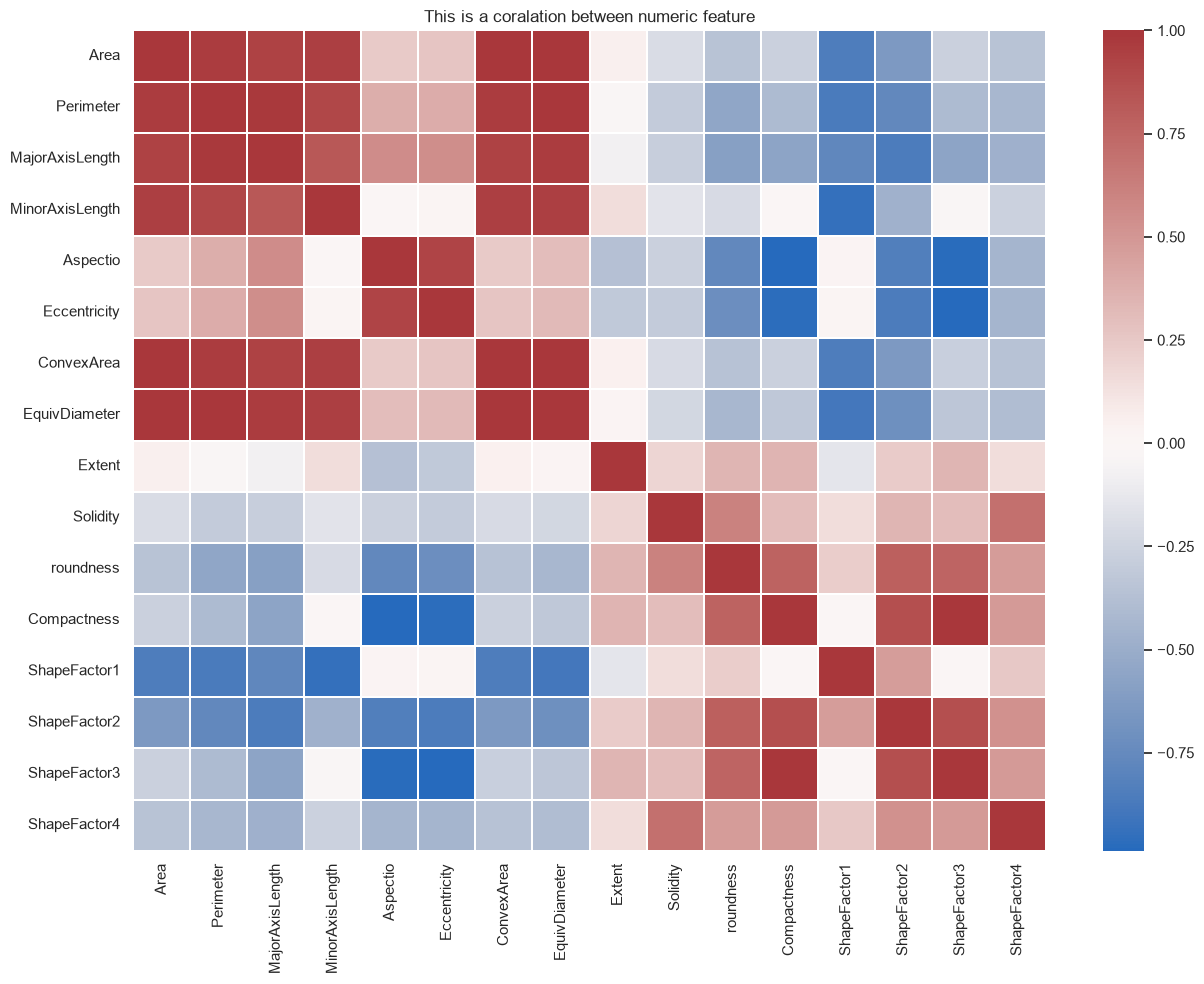

In [4]:
#this is for feature coralation of heatmap
plt.figure(figsize=(13,10))
corr=X.corr(numeric_only=True)
sns.heatmap(corr,cmap="vlag",center=0, square=False, linewidth=.2)
plt.title("This is a coralation between numeric feature")
plt.tight_layout();
plt.show()


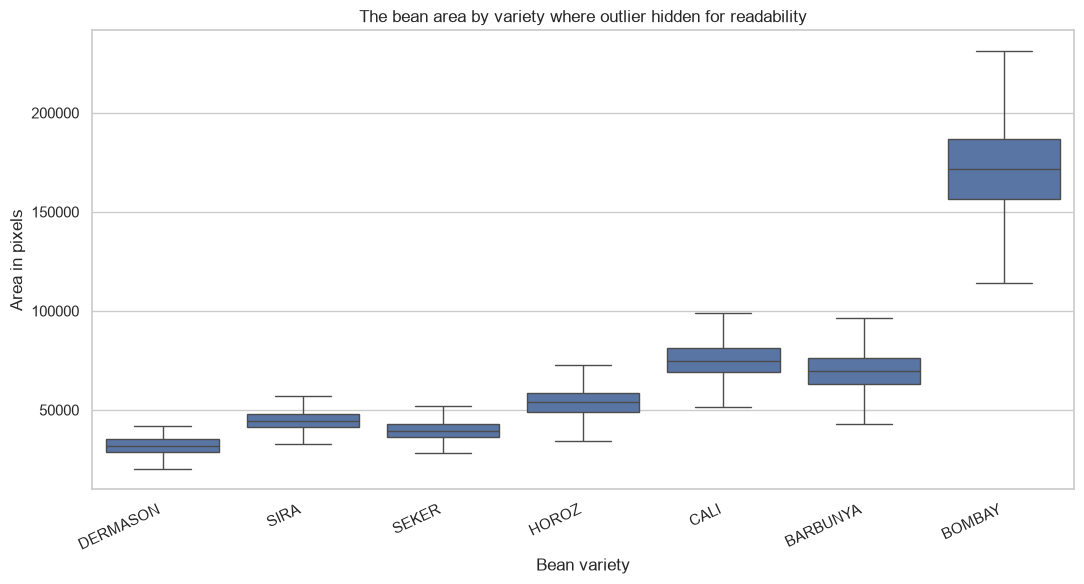

In [5]:
#this is area by class
plt.figure(figsize=(11,6))
sns.boxplot(data=df, x=TARGET, y="Area", order=order,showfliers=False)
plt.title("The bean area by variety where outlier hidden for readability")
plt.xlabel("Bean variety");plt.ylabel("Area in pixels")
plt.xticks(rotation=25, ha="right",)
plt.tight_layout();
plt.show()

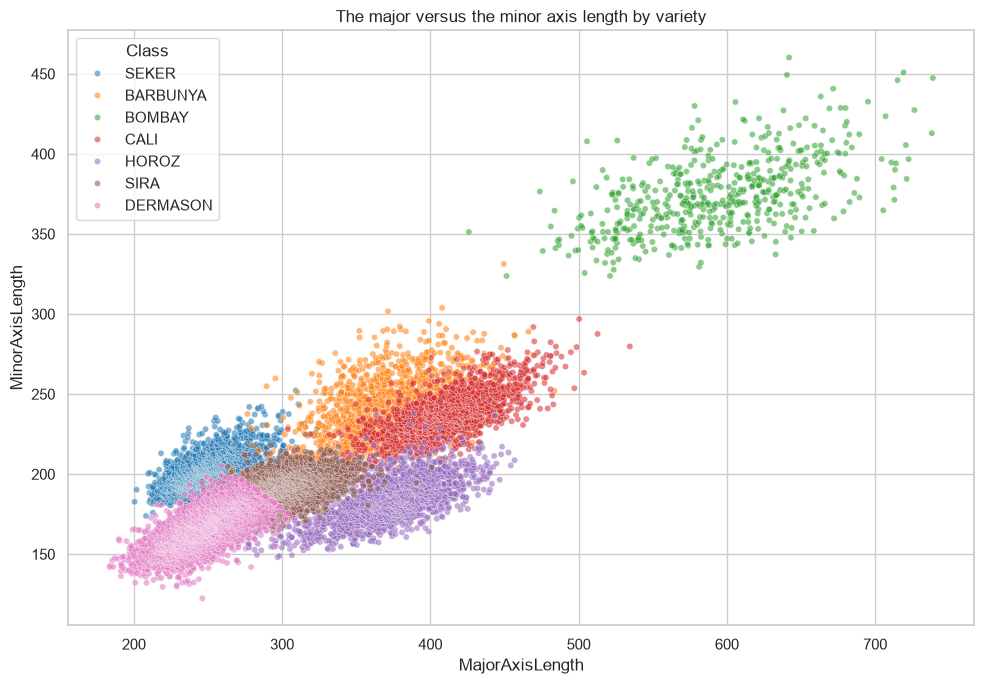

In [6]:
#The relation between two axes ( mojor and minor)
plt.figure(figsize=(10,7))
sns.scatterplot(data=df, x="MajorAxisLength", y="MinorAxisLength", hue=TARGET, alpha= .55, s=20, palette="tab10")
plt.title("The major versus the minor axis length by variety")
plt.tight_layout()
plt.show()

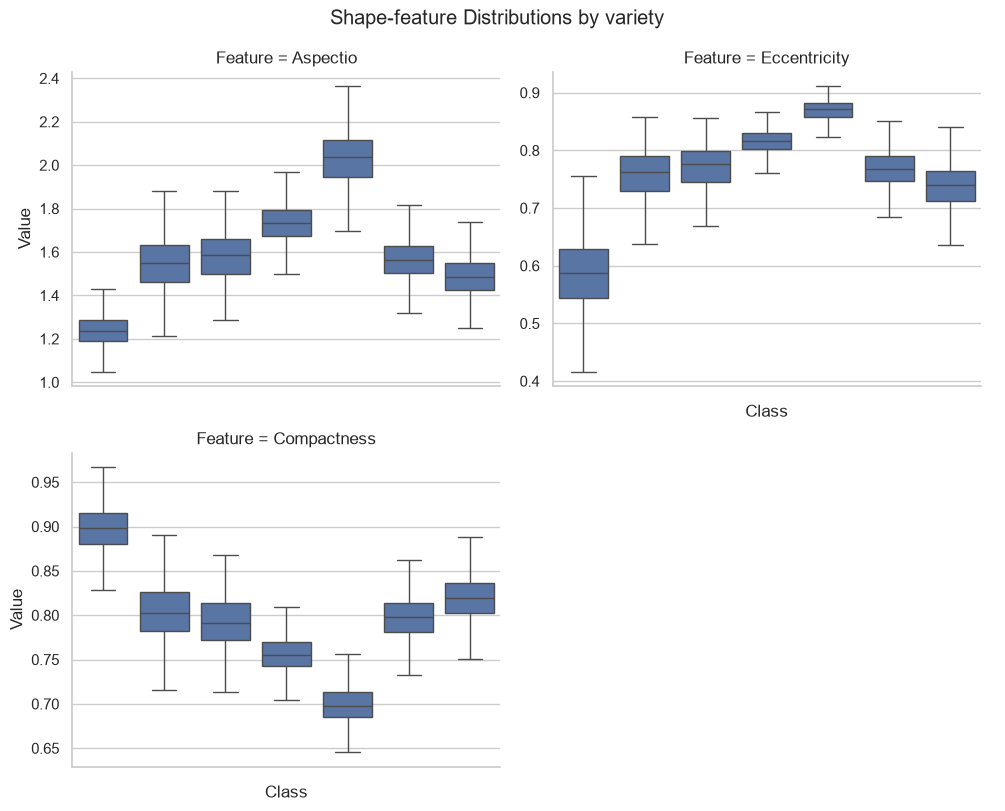

In [7]:
#Comparation bewteen several feature by class
selected_features = [c for c in ["Aspectio", "Eccentricity", "Compactness", "Roundness"] if c in X.columns]
long_df= df.melt(id_vars=TARGET, value_vars=selected_features, var_name="Feature", value_name="Value")
g = sns.catplot(data=long_df, x=TARGET, y="Value", col="Feature", kind="box", col_wrap= 2, sharey=False, showfliers=False, height=4, aspect=1.25)
g.set_xticklabels(rotation=30)
g.fig.suptitle("Shape-feature Distributions by variety", y=1.03)
plt.show()

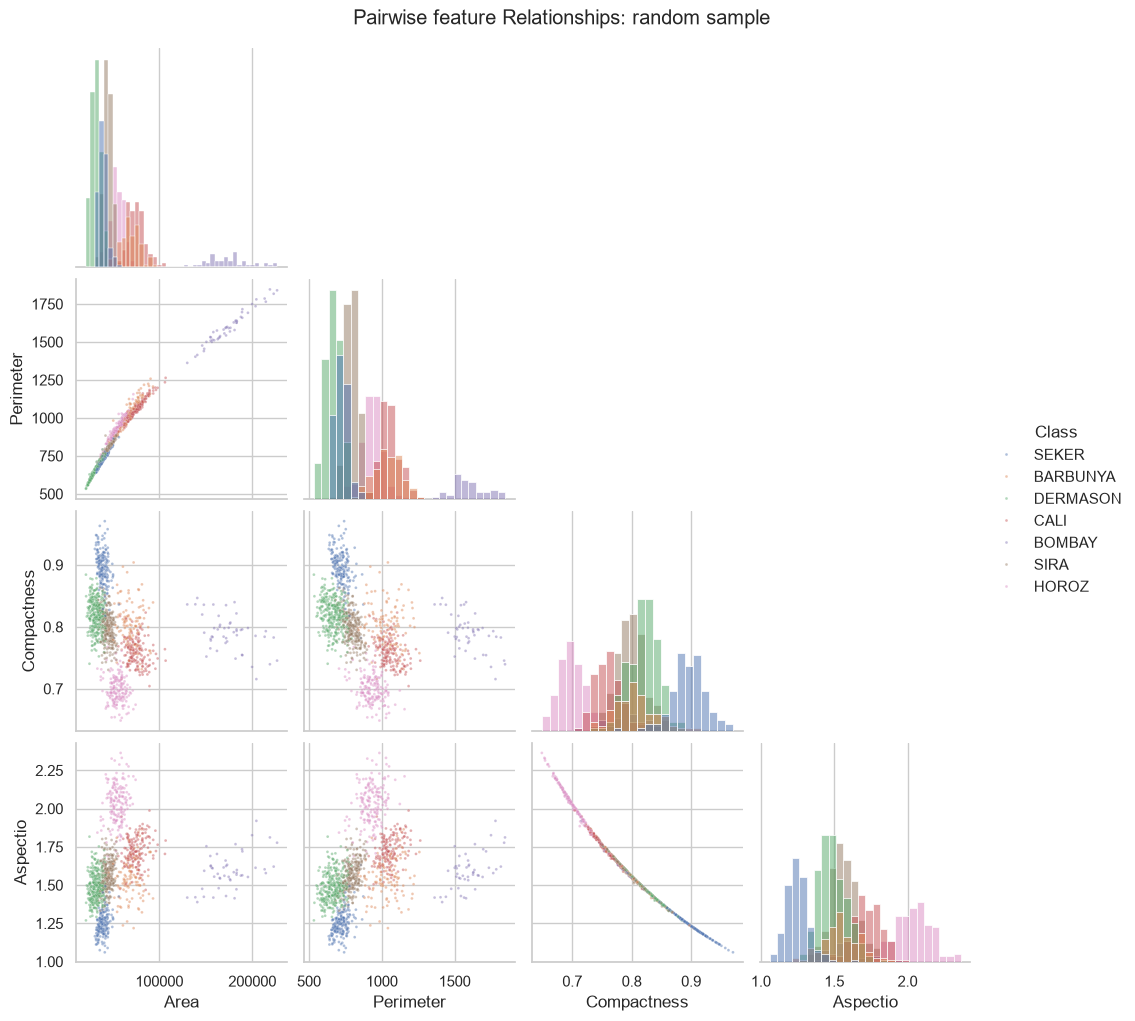

In [8]:
#Pairwise relationships on a manageable random sample
pair_features = [c for c in ["Area", "Perimeter", "Compactness", "Aspectio"] if c in X.columns]
pair_sample = df.sample(n=min(1200,len(df)), random_state=RANDOM_STATE)
sns.pairplot(pair_sample, vars=pair_features, hue=TARGET, corner=True, plot_kws={"alpha": .45, "s":4}, diag_kind="hist")
plt.suptitle("Pairwise feature Relationships: random sample", y=1.02)
plt.show()

In [9]:
#The table of strongest absolute feature correlation by excluding self-correlations
corr_pairs= corr.where(np.triu(np.ones(corr.shape), k=1) .astype(bool)).stack()
display(corr_pairs.abs().sort_values(ascending=False).head(12).rename("Absolute correlation").to_frame())

,,Absolute correlation
Area,ConvexArea,0.999939
Compactness,ShapeFactor3,0.998686
Perimeter,EquivDiameter,0.991380
Aspectio,Compactness,0.987687
ConvexArea,EquivDiameter,0.985226
Area,EquivDiameter,0.984968
Eccentricity,ShapeFactor3,0.981058
Aspectio,ShapeFactor3,0.978592
Perimeter,MajorAxisLength,0.977338
Eccentricity,Compactness,0.970313


## Data Preparation<a class="anchor" id="data_preparation"></a>

Stratified sampling was used to preserve class proportions. The dataset was divided into two parts: 80% for training and 20% for testing. Median
Imputation will be employed to handle missing numerical values. Imputation without scaling will be used for the decision tree and random forest models,
while "standarScaler" will be applied for logistic regression and SVM. Pipeline will be implemented to prevent data leakage. All 16 features will be
retained in their current form. Permutation importance will be used to identify the most influentiel features.

In [10]:
X_train,X_test,y_train,y_test=train_test_split(
    X,Y,test_size=0.20, random_state=RANDOM_STATE, stratify=Y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test) )
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame().round(3))
print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame().round(3))
def make_scaled_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model",estimator)
    ])

def make_tree_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model",estimator)
    ])

models={
    "Logistic Regression": make_scaled_pipeline(
        LogisticRegression(max_iter=3000, class_weight=None, random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_tree_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=2)
    ),
    "Random Forest": make_tree_pipeline(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                             random_state=RANDOM_STATE, n_jobs=-1)
    ),
    "Support Vector Machine": make_scaled_pipeline(
        SVC(C=3.0, kernel="rbf", gamma="scale")
    )     
}
print("Prepared", len(models), "candidate pipeline.")

Training rows: 10888 | Test rows: 2723

Training class proportions:


,proportion
Class,
BARBUNYA,0.097
BOMBAY,0.038
CALI,0.120
DERMASON,0.261
HOROZ,0.142
SEKER,0.149
SIRA,0.194



Test class proportions:


,proportion
Class,
BARBUNYA,0.097
BOMBAY,0.038
CALI,0.120
DERMASON,0.260
HOROZ,0.142
SEKER,0.149
SIRA,0.194


Prepared 4 candidate pipeline.


## Modeling<a class="anchor" id="modeling"></a>

Four machine learning algorithms will be compared such as logistic regression, decision tree, random forest, and support vector mchine (SVM). These
models were selected because they offer different approaches to classification. encompassing both linear and non-linear learning. making them 
particulary well-suited for this context. Their performance will be evaluated using stratified cross-validated using a rigorous process that ensures 
the accuracy and objectivity of the results. To identify the best-performing model for classifying the seven varieties of dry beans, the evaluation 
will be based on precision and the macro F1-score.

In [11]:
cv= StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring={
    "accuracy": "accuracy", "macro_f1": "f1_macro", "macro_precision": "precision_macro", "macro_recall":"recall_macro"
}
cv_rows=[]
for name,pipe in models.items():
    scores=cross_validate(pipe, X_train,y_train, cv=cv, scoring=scoring,
                         n_jobs=-1, return_train_score=False)
    cv_rows.append({
        "Model":name,
        "CV accuracy mean": scores["test_accuracy"].mean(),
        "CV accuracy std": scores["test_accuracy"].std(),
        "CV macro F1 mean": scores["test_macro_f1"].mean(),
        "CV macro precision mean": scores["test_macro_precision"].mean(),
        "CV macro recall mean": scores["test_macro_recall"].mean()
    })
    cv_results = pd.DataFrame(cv_rows).sort_values("CV macro F1 mean",ascending=False).reset_index(drop=True)
    display(cv_results.style.format({c:"{:.4f}" for c in cv_results.columns if c != "Model"}))
    best_name=cv_results.loc[0, "Model"]
    best_model = models[best_name]
    print("Selected model by mean training CV macro F1:", best_name)
    best_model.fit(X_train, y_train)
    y_pred = best_model.predict(X_test)

,Model,CV accuracy mean,CV accuracy std,CV macro F1 mean,CV macro precision mean,CV macro recall mean
0,Logistic Regression,0.9242,0.0038,0.9356,0.9369,0.9348


Selected model by mean training CV macro F1: Logistic Regression


,Model,CV accuracy mean,CV accuracy std,CV macro F1 mean,CV macro precision mean,CV macro recall mean
0,Logistic Regression,0.9242,0.0038,0.9356,0.9369,0.9348
1,Decision Tree,0.8950,0.0024,0.9082,0.9081,0.9088


Selected model by mean training CV macro F1: Logistic Regression


,Model,CV accuracy mean,CV accuracy std,CV macro F1 mean,CV macro precision mean,CV macro recall mean
0,Logistic Regression,0.9242,0.0038,0.9356,0.9369,0.9348
1,Random Forest,0.9245,0.0059,0.9356,0.9370,0.9345
2,Decision Tree,0.8950,0.0024,0.9082,0.9081,0.9088


Selected model by mean training CV macro F1: Logistic Regression


,Model,CV accuracy mean,CV accuracy std,CV macro F1 mean,CV macro precision mean,CV macro recall mean
0,Support Vector Machine,0.9327,0.0051,0.9439,0.9457,0.9424
1,Logistic Regression,0.9242,0.0038,0.9356,0.9369,0.9348
2,Random Forest,0.9245,0.0059,0.9356,0.9370,0.9345
3,Decision Tree,0.8950,0.0024,0.9082,0.9081,0.9088


Selected model by mean training CV macro F1: Support Vector Machine


## Evaluation<a class="anchor" id="evaluation"></a>

To evaluate the models, several metrics will be used such as accuracy, precision, recall, the macro F1-score, and the confusion matrix. Stratified
cross-validation will be employed to compare model performance on the training data. The generalization capability of the selected model will be 
assessed using a separate test set. the macro F1-score is particularly important, as it accounts for the class imbalance among the seven bean 
categories. Permutation analysis will be used to identify influential features and to provide explainations for the models predictions. The final model
will be chosen based on these evaluation results. which will serve as the fundation for selecting the model that best meets the client's needs.

In [12]:
test_results= pd.DataFrame([{
    "Selected model": best_name,
    "Test accuracy": accuracy_score(y_test, y_pred),
    "Test macro precision": precision_score(y_test,y_pred, average="macro", zero_division=0),
    "Test macro recall": recall_score(y_test,y_pred, average="macro", zero_division=0),
    "Test macro F1" : f1_score(y_test,y_pred, average="macro", zero_division=0),
    "Test weighted F1": f1_score(y_test,y_pred, average="weighted", zero_division=0)
}])
display(test_results.round(4))
print(classification_report(y_test,y_pred,digits=4,zero_division=0))

,Selected model,Test accuracy,Test macro precision,Test macro recall,Test macro F1,Test weighted F1
0,Support Vector Machine,0.9229,0.936,0.934,0.935,0.9229


              precision    recall  f1-score   support

    BARBUNYA     0.9341    0.9094    0.9216       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9387    0.9387    0.9387       326
    DERMASON     0.9119    0.9196    0.9157       709
       HOROZ     0.9609    0.9560    0.9584       386
       SEKER     0.9415    0.9507    0.9461       406
        SIRA     0.8650    0.8634    0.8642       527

    accuracy                         0.9229      2723
   macro avg     0.9360    0.9340    0.9350      2723
weighted avg     0.9229    0.9229    0.9229      2723



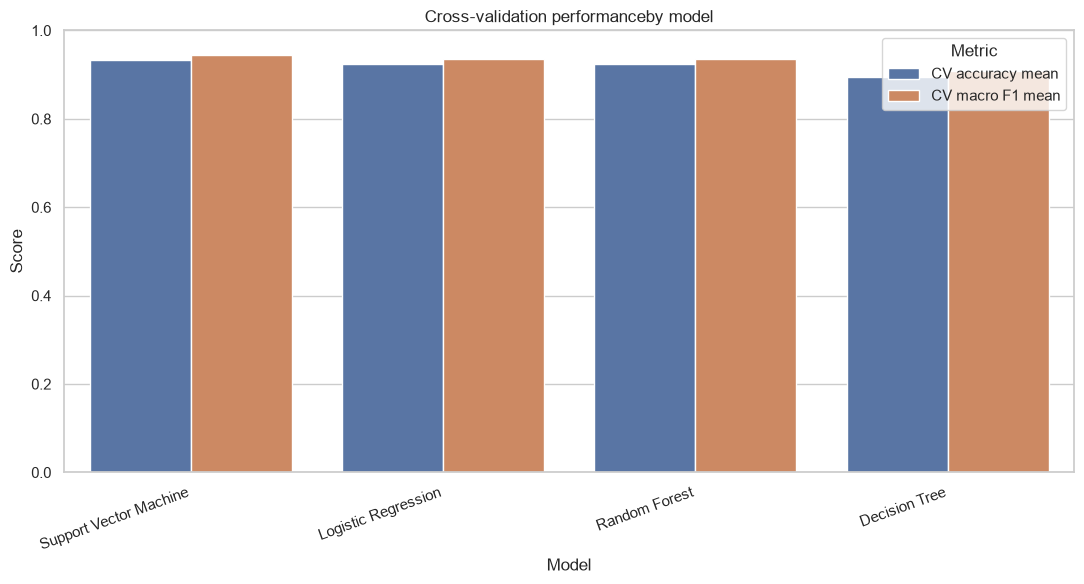

In [13]:
#compare cross-validationmetrics
plot_df=cv_results.melt(id_vars="Model",
                       value_vars=["CV accuracy mean", "CV macro F1 mean"],
                       var_name="Metric", value_name="Score")
plt.figure(figsize=(11,6))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Cross-validation performanceby model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

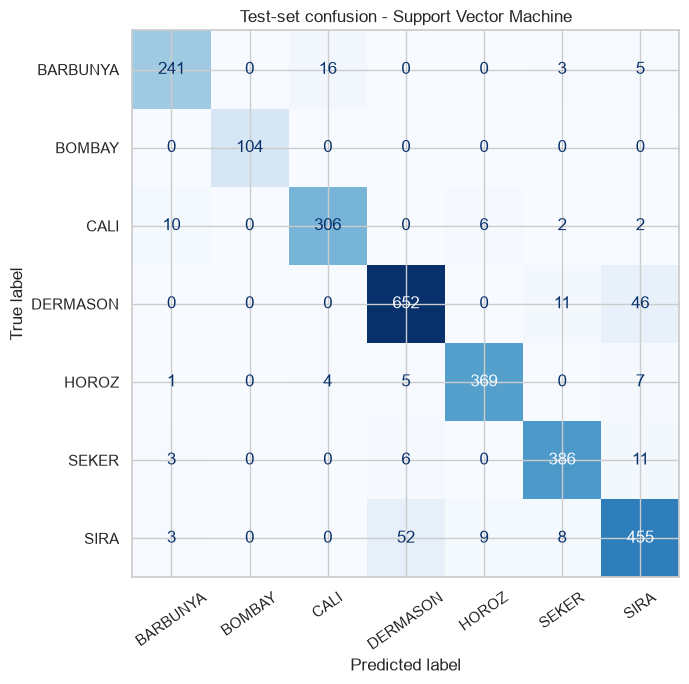

In [14]:
#confusion matrix for selected model
fig, ax= plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,normalize=None,
                                      xticks_rotation=35, cmap="Blues", ax=ax, colorbar= False )
ax.set_title(f"Test-set confusion - {best_name}")
plt.tight_layout()
plt.show()

,Bean variety,Test F1
1,BOMBAY,1.0000
4,HOROZ,0.9584
5,SEKER,0.9461
2,CALI,0.9387
0,BARBUNYA,0.9216
3,DERMASON,0.9157
6,SIRA,0.8642


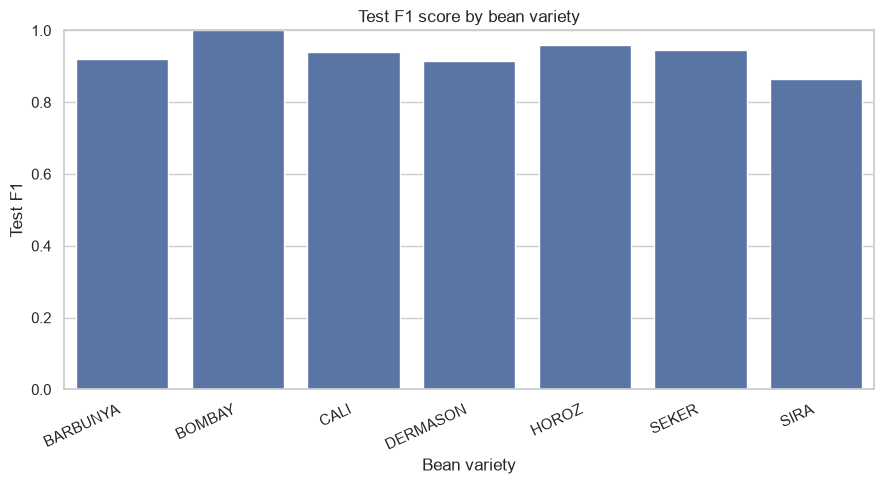

In [15]:
#Per-class test F1
per_class_f1 = f1_score(y_test, y_pred, average=None, labels= best_model.classes_)
class_f1_df = pd.DataFrame({"Bean variety": best_model.classes_, "Test F1": per_class_f1})
display(class_f1_df.sort_values("Test F1", ascending=False).round(4))
plt.figure(figsize=(9,5))
sns.barplot(data=class_f1_df, x="Bean variety", y = "Test F1")
plt.ylim(0,1)
plt.title("Test F1 score by bean variety")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

,Feature,Mean decrease in macro F1,Standard deviation
10,roundness,0.09827,0.00477
15,ShapeFactor4,0.08363,0.00574
12,ShapeFactor1,0.04631,0.00120
3,MinorAxisLength,0.02137,0.00229
1,Perimeter,0.01994,0.00153
4,Aspectio,0.01967,0.00153
5,Eccentricity,0.01800,0.00285
7,EquivDiameter,0.01674,0.00275
14,ShapeFactor3,0.01549,0.00300
11,Compactness,0.01492,0.00317


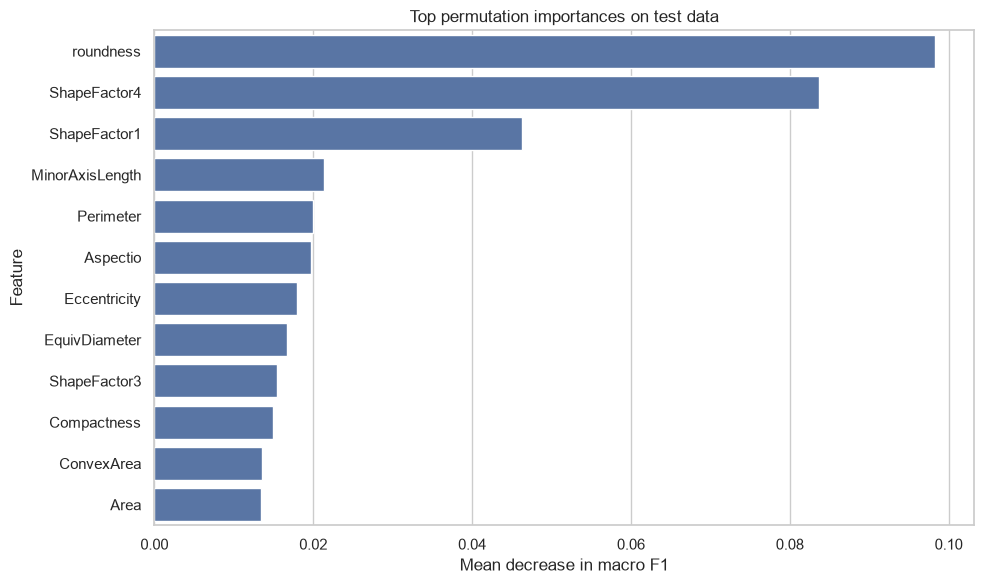

In [16]:
#permutation importance
perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Mean decrease in macro F1": perm.importances_mean,
    "Standard deviation": perm.importances_std
}).sort_values("Mean decrease in macro F1", ascending= False)
display(importance_df.head(12).round(5))
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(12), x="Mean decrease in macro F1", y= "Feature")
plt.title("Top permutation importances on test data")
plt.tight_layout()
plt.show()

## References<a class="anchor" id="references"></a>

Khan, M. S., Nath, T. D., Hossain, M. M., Mukherjee, A., Hasnath, H. B., Meem, T. M., & Khan, U. (2023). Comparison of multiclass classification techniques using dry bean dataset. International Journal of Cognitive Computing in Engineering, 4, 6-20.
    
Koklu, M., & Ozkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. Computers and Electronics in Agriculture, 174, 105507.

List all the sources you used during your work.
This includes jupyter notebooks you found on Internet.
Remember, your work may not be an original one. However, this document must be genuine. Copy and paste kind of deliveries are not allowed.

In [ ]:
https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
https://scikit-learn.org/stable/index.html
https://pandas.pydata.org/docs/index.html
https://seaborn.pydata.org/#


**Disclaimer!** <font color='grey'>This notebook was prepared by Ousmane DIALLO as a term project. The notebook is available for educational purposes only. There is no guarantee on the correctness of the content provided as it is a student work.
</font>